
# Pitch Basics

First we import the Pitch classes and matplotlib


In [1]:
%%script false --no-raise-error

!pip install mplsoccer pandas-summary

import matplotlib.pyplot as plt

from mplsoccer import Pitch, VerticalPitch

plt.rcdefaults() # cancel the xqcd

## Draw a pitch on a new axis
Let's plot on a new axis first.



In [2]:
# import csv

# # Define the path to your CSV file
# csv_file_path = 'Session-Mateo-gps.csv'

# # Initialize an empty list to store the data
# sheet = []

# # Open and read the CSV file
# with open(csv_file_path, 'r') as file:
#     csv_reader = csv.reader(file)
#     header = next(csv_reader)  # Read the header row (if it exists)
#     sheet.append(header)  # Add the header to the data list (optional)
    
#     for row in csv_reader:
#         sheet.append(row)

# # Display the data
# for row in sheet[:10]:
#     print(row)

In [3]:
import pandas as pd
csv_file_path = 'Session_28-10-2023.csv'
df = pd.read_csv(csv_file_path)
df.columns = ['Player Display Name', 'Time', 'Elapsed Time (s)', 'Lat', 'Lon', 'Speed km/h', 'Instantaneous Acceleration Impulse', 'Heart Rate (bpm)', 'basura']
df.columns = df.columns.str.strip()

#https://www.google.com/maps/place/34%C2%B047'45.4%22S+56%C2%B008'51.9%22W/@-34.7954353,-56.1481298,189m/data=!3m1!1e3!4m4!3m3!8m2!3d-34.7959307!4d-56.1477602?entry=ttu
# -34.794926, -56.148368
# -34.795816, -56.147428

lat_lower_bound = -34.795816
lat_upper_bound = -34.794926
lon_lower_bound = -56.148368
lon_upper_bound = -56.147428
fix_df = df[(df['Lat'] > lat_lower_bound) & (df['Lat'] < lat_upper_bound)]
fix_df = fix_df[(fix_df['Lon'] > lon_lower_bound) & (fix_df['Lon'] < lon_upper_bound)]

In [4]:
fix_df

,Player Display Name,Time,Elapsed Time (s),Lat,Lon,Speed km/h,Instantaneous Acceleration Impulse,Heart Rate (bpm),basura
42,Fran Dennis,11:04:41.60,1622.400002,-34.794928,-56.147491,5.830005,4.900004,0,NaN
42,Fran Dennis,11:04:41.70,1622.500001,-34.794929,-56.147491,5.730005,1.000001,0,NaN
42,Fran Dennis,11:04:41.80,1622.600001,-34.794930,-56.147491,5.590004,1.400001,0,NaN
42,Fran Dennis,11:04:41.90,1622.700000,-34.794932,-56.147491,5.410004,1.800001,0,NaN
42,Fran Dennis,11:04:42.00,1622.800000,-34.794933,-56.147491,5.300004,1.100001,0,NaN
...,...,...,...,...,...,...,...,...,...
166,Rodriguez Luciano,13:32:19.00,59539.000000,-34.795800,-56.147849,15.730013,0.300000,45,NaN
166,Rodriguez Luciano,13:32:19.10,59539.100000,-34.795804,-56.147850,15.710013,0.200000,45,NaN
166,Rodriguez Luciano,13:32:19.20,59539.199999,-34.795808,-56.147851,15.690013,0.200000,45,NaN
166,Rodriguez Luciano,13:32:19.30,59539.299998,-34.795811,-56.147851,15.680013,0.100000,45,NaN



# Analisis Descriptivo


In [5]:
summary_lon = fix_df['Lon'].describe()
summary_lat = fix_df['Lat'].describe()

print("summary_lon:\n", summary_lon)
print("summary_lat:\n", summary_lat)

summary_lon:
 count    552749.000000
mean        -56.147823
std           0.000203
min         -56.148344
25%         -56.147964
50%         -56.147832
75%         -56.147671
max         -56.147428
Name: Lon, dtype: float64
summary_lat:
 count    552749.000000
mean        -34.795362
std           0.000204
min         -34.795816
25%         -34.795511
50%         -34.795362
75%         -34.795196
max         -34.794926
Name: Lat, dtype: float64


In [6]:
from pandas_summary import DataFrameSummary

# Get a summary of the DataFrame

numeric_columns = fix_df.select_dtypes(include=['number'])

summary = DataFrameSummary(numeric_columns)

# Print the summary
print(summary.summary())

             Elapsed Time (s)        Lat        Lon Speed km/h  \
count                552749.0   552749.0   552749.0   552749.0   
mean             20305.831054 -34.795362 -56.147823   5.516483   
std              23083.770263   0.000204   0.000203   4.711358   
min               1259.700008 -34.795816 -56.148344        0.0   
25%               3593.000004 -34.795511 -56.147964   2.560002   
50%                    6307.1 -34.795362 -56.147832   4.590004   
75%              52016.199995 -34.795196 -56.147671   6.690005   
max              59539.399998 -34.794926 -56.147428  43.110034   
counts                 552749     552749     552749     552749   
uniques                251486       5339       5391       2916   
missing                     0          0          0          0   
missing_perc               0%         0%         0%         0%   
types                 numeric    numeric    numeric    numeric   

             Instantaneous Acceleration Impulse Heart Rate (bpm)   basura  

In [7]:
# Get the minimum and maximum values for 'Column1'
min_value_lat = fix_df['Lat'].min()
max_value_lat = fix_df['Lat'].max()

# Get the minimum and maximum values for 'Column2'
min_value_lon = fix_df['Lon'].min()
max_value_lon = fix_df['Lon'].max()

print(f"Minimum of player min_value_lat: {min_value_lat}")
print(f"Maximum of player max_value_lat: {max_value_lat}")
print(f"Minimum of player min_value_lon: {min_value_lon}")
print(f"Maximum of player max_value_lon: {max_value_lon}")

Minimum of player min_value_lat: -34.79581583
Maximum of player max_value_lat: -34.79492617
Minimum of player min_value_lon: -56.148344
Maximum of player max_value_lon: -56.14742817


In [8]:
# puntos en cancha
# https://www.google.com/maps/place/34%C2%B047'45.4%22S+56%C2%B008'51.9%22W/@-34.7954353,-56.1481298,189m/data=!3m1!1e3!4m4!3m3!8m2!3d-34.7959307!4d-56.1477602?entry=ttu

# -34.794926, -56.148368
# -34.795816, -56.147428

# Coordenadas de Los cespedes
lat_min = -34.795816
lat_max = -34.794926
lon_min = -56.148368
lon_max = -56.147428


# Trigonometria


In [9]:
import numpy as np

# Define the GPS coordinates of four points (A, B, C, D) on the field
point_A = (-34.794927, -56.148375)
point_B = (-34.794853, -56.147571)
point_C = (-34.795902, -56.148234)
point_D = (-34.795815, -56.147426)

# Calculate the length and width of the rectangle
length = np.sqrt((point_A[0] - point_B[0])**2 + (point_A[1] - point_B[1])**2)
width = np.sqrt((point_A[0] - point_C[0])**2 + (point_A[1] - point_C[1])**2)

# Determine which sides are length and width
if length > width:
    length, width = width, length  # Swap if necessary

# Calculate the angle between the length side and the North direction
rotation_angle_radians = np.arctan2(point_B[1] - point_A[1], point_B[0] - point_A[0])
rotation_angle_degrees = np.degrees(rotation_angle_radians)

# Ensure the angle is positive (between 0 and 360 degrees)
if rotation_angle_degrees < 0:
    rotation_angle_degrees += 360

print(f"Rotation Angle: {rotation_angle_degrees} degrees")

Rotation Angle: 84.74132377744776 degrees



# Normalizacion de las coordenadas para el Pitch


In [59]:
import pandas as pd
import numpy as np

# Define the rotation angle in degrees
rotation_angle_degrees = 84.74132377744776  # Degrees rotated from North to West

# Convert the rotation angle to radians
rotation_angle_radians = np.radians(rotation_angle_degrees)

# Define the size of the soccer field in meters
soccer_field_length = 80  # In meters
soccer_field_width = 120  # In meters

# Function to apply the rotation to coordinates
def rotate_coordinates(row):
    lat, lon = row['Lat'], row['Lon']
    new_lat = lat * np.cos(rotation_angle_radians) - lon * np.sin(rotation_angle_radians)
    new_lon = lat * np.sin(rotation_angle_radians) + lon * np.cos(rotation_angle_radians)
    return pd.Series({'Lat': new_lat, 'Lon': new_lon})


df = fix_df
# Apply the rotation to the coordinates
df[['Lat', 'Lon']] = df.apply(rotate_coordinates, axis=1)

# Scale and normalize the coordinates to the soccer field dimensions
df['Lat_normalized'] = (df['Lat'] - df['Lat'].min()) / (df['Lat'].max() - df['Lat'].min()) * soccer_field_length
df['Lon_normalized'] = (df['Lon'] - df['Lon'].min()) / (df['Lon'].max() - df['Lon'].min()) * soccer_field_width


# Display the DataFrame with normalized coordinates
df.head()


    Player Display Name         Time  Elapsed Time (s)        Lat        Lon  \
42         Fran Dennis   11:04:41.60       1622.400002  44.459148  48.852961   
42         Fran Dennis   11:04:41.70       1622.500001  44.459150  48.852961   
42         Fran Dennis   11:04:41.80       1622.600001  44.459151  48.852961   
42         Fran Dennis   11:04:41.90       1622.700000  44.459153  48.852961   
42         Fran Dennis   11:04:42.00       1622.800000  44.459154  48.852960   
..                  ...          ...               ...        ...        ...   
166  Rodriguez Luciano   13:32:19.00      59539.000000  44.460072  48.853155   
166  Rodriguez Luciano   13:32:19.10      59539.100000  44.460076  48.853155   
166  Rodriguez Luciano   13:32:19.20      59539.199999  44.460079  48.853155   
166  Rodriguez Luciano   13:32:19.30      59539.299998  44.460083  48.853155   
166  Rodriguez Luciano   13:32:19.40      59539.399998  44.460087  48.853155   

     Speed km/h  Instantaneous Accelera

In [60]:
df_backed_up = df


# Visualizacion


552749


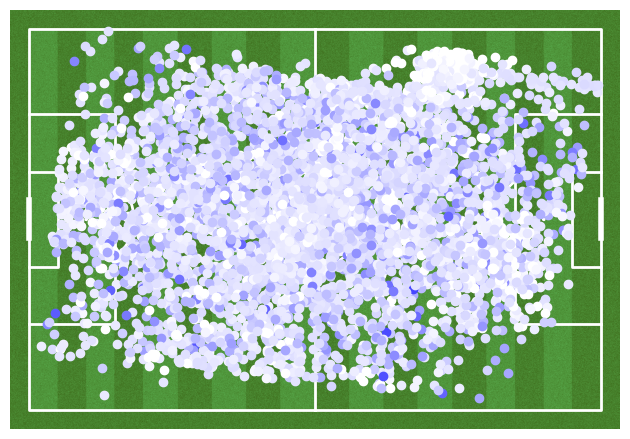

In [11]:
pitch = Pitch(pitch_color='grass', line_color='white',
              stripe=True)  # optional stripes
fig, ax = pitch.draw()


print(len(df))

# cancha: 120x80

step = 100
colors = np.linspace(0, 1, len(df))
# Iterar avanzando de 10 en 10 elementos
for i in range(0, len(df), step):
    # color = (1, 1 - colors[i], 1 - colors[i])
    for index, row in df.iloc[i:i+1].iterrows():
        # print(row['Lat_normalized'],row['Lon_normalized'])
        speed = row['Speed km/h']
        normalized_speed = (speed - df['Speed km/h'].min()) / (df['Speed km/h'].max() - df['Speed km/h'].min())
        color = (1 - normalized_speed, 1 - normalized_speed, 1)  # Gradual transition from white to blue
        ax.scatter(row['Lon_normalized'], row['Lat_normalized'], c=color)


plt.show()

In [12]:
speed_df = fix_df[fix_df['Speed km/h'] > 0.5]

In [50]:
def plot_velocidades_altas(v_min, subtitle=None ,use_df=None, v_max=None, color_param='R', step=1):
    pitch = Pitch(pitch_color='#aabb97', line_color='white',
              stripe_color='#c2d59d', stripe=True)  # optional stripes
    fig, ax = pitch.draw()
    if use_df is not None:
        fix_df = use_df 
    
    speed_df = fix_df[fix_df['Speed km/h'] > v_min]
    str = f'Velocidades > {v_min}km/h'
    
    if v_max:
        speed_df = speed_df[speed_df['Speed km/h'] < v_max]
        str = f'{str} y < {v_max}km/h'
    
    df = speed_df
    
    print(subtitle, "Total de puntos: ", len(df))
    annotation = ax.annotate(str, (60, 10), fontsize=20, ha='center', color="green")
    annotation_2 = ax.annotate(subtitle, (60, 20), fontsize=10, ha='center', color="green")
    
    # cancha: 120x80
    colors = np.linspace(0, 1, len(df))
    # Iterar avanzando de 10 en 10 elementos
    for i in range(0, len(df), step):
        # color = (1, 1 - colors[i], 1 - colors[i])
        for index, row in df.iloc[i:i+1].iterrows():
            # print(row['Lat_normalized'],row['Lon_normalized'])
            speed = row['Speed km/h']
            normalized_speed = (speed - df['Speed km/h'].min()) / (df['Speed km/h'].max() - df['Speed km/h'].min())
            if color_param == 'R':
                color = (1 - normalized_speed, 0, 0)  # Rojo
            elif color_param == 'G':
                color = (0, 1 - normalized_speed, 0)  # Verde
            elif color_param == 'B':
                color = (0, 0, 1 - normalized_speed)  # Azul
            else:
                color = (1, 1, 1)  # Blanco por defecto
            ax.scatter(row['Lon_normalized'], row['Lat_normalized'], c=color)

Total de puntos:  1698


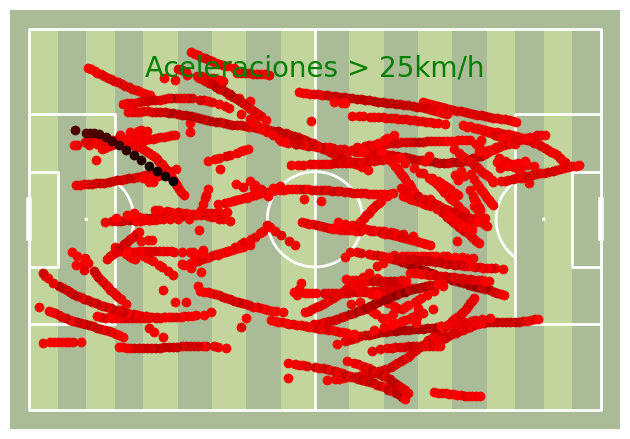

In [14]:
plot_velocidades_altas(25)

Total de puntos:  7223


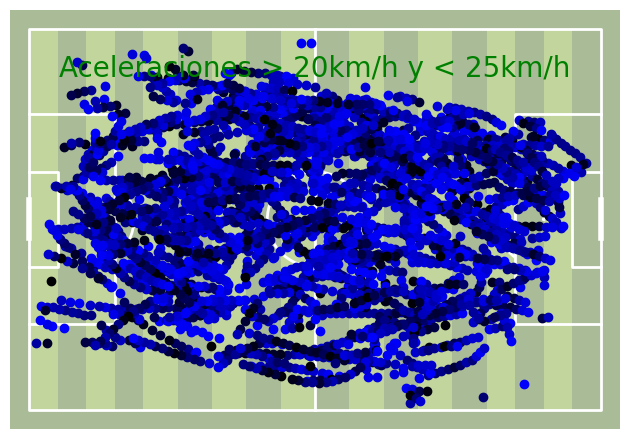

In [15]:
plot_velocidades_altas(20, v_max=25, color_param='B', step=2)

Total de puntos:  20503


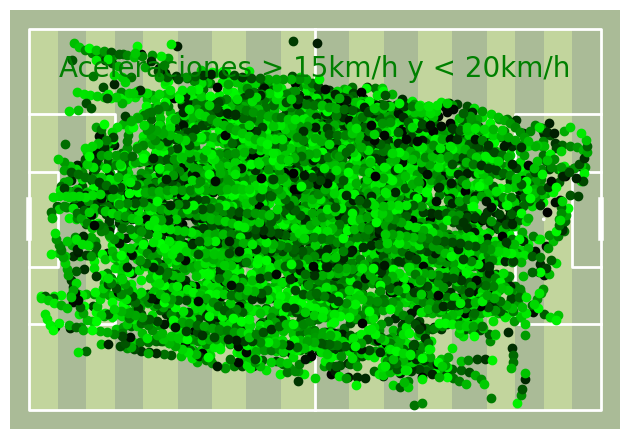

In [16]:
plot_velocidades_altas(15, v_max=20, color_param='G', step=3)

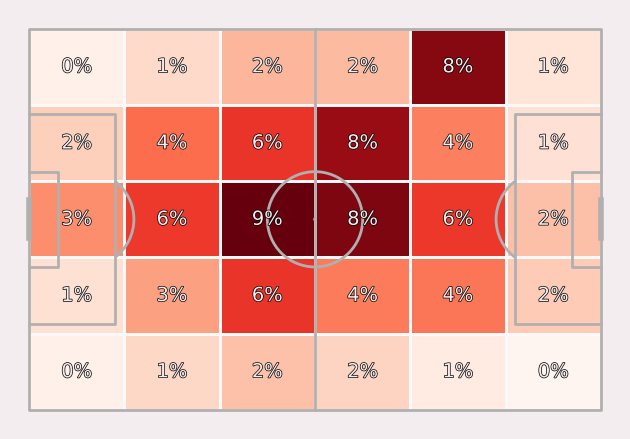

In [17]:
import matplotlib.patheffects as path_effects

path_eff = [path_effects.Stroke(linewidth=1, foreground='black'),
            path_effects.Normal()]

pitch = Pitch(pitch_type='statsbomb', line_zorder=2, pitch_color='#f4edf0')
fig, ax = pitch.draw()
fig.set_facecolor('#f4edf0')

df = fix_df

bin_statistic = pitch.bin_statistic(df['Lon_normalized'], df['Lat_normalized'], statistic='count', bins=(6, 5), normalize=True)
pitch.heatmap(bin_statistic, ax=ax, cmap='Reds', edgecolor='#f9f9f9')
labels = pitch.label_heatmap(bin_statistic, color='#f4edf0', fontsize=14,
                             ax=ax, ha='center', va='center',
                             str_format='{:.0%}', path_effects=path_eff)

In [18]:
import math

df = fix_df
df = df[df['Elapsed Time (s)'] > 0]

# Apply the rotation to the coordinates
df['coord'] = list(zip(df['Lat'], df['Lon'], df['Elapsed Time (s)']))
# Sample GPS coordinate data (latitude, longitude, timestamp)
gps_data = df['coord']

# Function to calculate distance between two GPS coordinates
def calculate_distance(coord1, coord2):
    lat1, lon1, _ = coord1
    lat2, lon2, _ = coord2
    radius = 6371  # Earth's radius in kilometers
    lat1_rad = math.radians(lat1)
    lon1_rad = math.radians(lon1)
    lat2_rad = math.radians(lat2)
    lon2_rad = math.radians(lon2)
    delta_lat = lat2_rad - lat1_rad
    delta_lon = lon2_rad - lon1_rad
    a = math.sin(delta_lat / 2)**2 + math.cos(lat1_rad) * math.cos(lat2_rad) * math.sin(delta_lon / 2)**2
    c = 2 * math.atan2(math.sqrt(a), math.sqrt(1 - a))
    distance = radius * c
    return distance

# Threshold speed in km/h
threshold_speed = 20

# Variables to keep track of total distance and distance above threshold
total_distance = 0
distance_above_threshold = 0

for i in range(len(df) - 1):
    coord1 = df['coord'].iloc[i]
    coord2 = df['coord'].iloc[i + 1]

    # Calculate the distance between two consecutive coordinates
    distance = calculate_distance(coord1, coord2)

    # Calculate the time elapsed between coordinates (in seconds)
    time_elapsed = 0.1 
    # time_elapsed ----> coord2[2] - coord1[2]
    # print(time_elapsed)

    # Calculate speed (distance / time) in km/h
    speed = (distance / time_elapsed) * 3600

    # Update total distance
    total_distance += distance

    # Check if speed is above the threshold
    if speed >= threshold_speed:
        distance_above_threshold += distance

print(f"Total distance run: {total_distance} km")
print(f"Distance above {threshold_speed} km/h: {distance_above_threshold} km")

Total distance run: 75.74827826491808 km
Distance above 20 km/h: 4.095969477098117 km


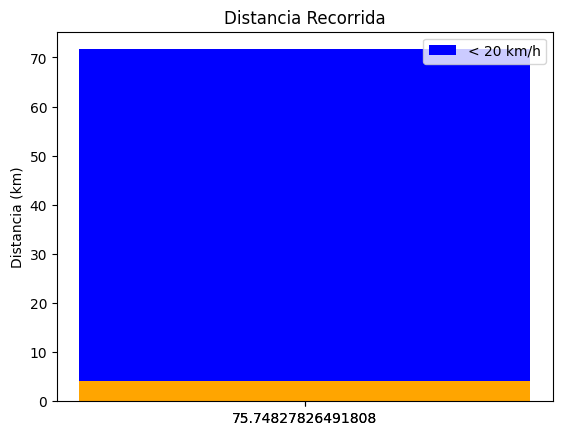

In [19]:
import matplotlib.pyplot as plt

# Distancia recorrida por debajo de threshold_speed km/h
distance_below_threshold = total_distance - distance_above_threshold

# Colores para los segmentos
colors = ['blue', 'orange']

# Etiquetas para los segmentos
labels = [f'< {threshold_speed} km/h', f'>= {threshold_speed} km/h']

# Alturas de los segmentos
heights = [distance_below_threshold, distance_above_threshold]

# Posiciones en el eje X para los segmentos
positions = [0, 0]

# Crear la figura y los ejes
fig, ax = plt.subplots()

# Dibujar el segmento de la barra
ax.bar(positions, heights, color=colors, tick_label=[total_distance])

# Configurar el eje y
ax.set_ylabel('Distancia (km)')

# Configurar el título
ax.set_title('Distancia Recorrida')

# Añadir una leyenda
ax.legend(labels)

# Mostrar la gráfica
plt.show()

In [33]:
import pandas as pd


# Crear un DataFrame de ejemplo con coordenadas y velocidad
df = fix_df

# km/h => m/s
df['Speed m/s'] = list(df['Speed km/h']/3.6)
# df['Acceleration'] = list(df['Speed km/h']/3.6)

# Umbral de aceleración
threshold_acceleration = 4.9  # Ajusta el umbral según sea necesario


# Contador de veces que se supera el umbral de aceleración
count_exceeding_threshold = 0

rows_per_second = 10

when = []

# Iterar a través del DataFrame con saltos de 10 filas
for i in range(0, len(df) - rows_per_second, rows_per_second):
    # Obtener la velocidad actual y la velocidad anterior
    velocity_current = df['Speed m/s'].iloc[i]
    velocity_next = df['Speed m/s'].iloc[i + rows_per_second]

    # Calcular la aceleración como cambio en la velocidad dividido por el tiempo (1 segundo)
    acceleration = (velocity_next - velocity_current) / 1.0

    # Comparar la aceleración con el umbral
    if acceleration > threshold_acceleration:
        when.append([i])
        count_exceeding_threshold += 1

print(f"El umbral de aceleración se superó {count_exceeding_threshold} veces.")


El umbral de aceleración se superó 1 veces.


In [34]:
when

[[552680]]

In [53]:
df_resultado

,Player Display Name,Time,Elapsed Time (s),Lat,Lon,Speed km/h,Instantaneous Acceleration Impulse,Heart Rate (bpm),basura,Lat_normalized,Lon_normalized,Speed m/s
166,Rodriguez Luciano,13:02:54.60,57774.600000,52.722153,-39.794547,4.590004,0.800001,45,NaN,13.753784,117.190627,1.275001
166,Rodriguez Luciano,13:02:54.70,57774.700000,52.722153,-39.794546,3.770003,8.200007,45,NaN,13.732565,117.297390,1.047223
166,Rodriguez Luciano,13:02:54.80,57774.799998,52.722153,-39.794545,3.370003,4.000003,45,NaN,13.754490,117.419538,0.936112
166,Rodriguez Luciano,13:02:54.90,57774.899998,52.722153,-39.794544,3.500003,1.300001,45,NaN,13.791111,117.560953,0.972223
166,Rodriguez Luciano,13:02:55.00,57774.999997,52.722154,-39.794543,3.690003,1.900002,45,NaN,13.800121,117.706138,1.025001
166,Rodriguez Luciano,13:02:55.10,57775.099997,52.722154,-39.794542,3.980003,2.900002,45,NaN,13.836665,117.846312,1.105556
166,Rodriguez Luciano,13:02:55.20,57775.199996,52.722155,-39.794541,4.610004,6.300005,45,NaN,13.903043,118.004939,1.280557
166,Rodriguez Luciano,13:02:55.30,57775.300004,52.722155,-39.794540,4.490004,1.200001,45,NaN,13.953812,118.143172,1.247223
166,Rodriguez Luciano,13:02:55.40,57775.400003,52.722155,-39.794538,3.660003,8.300007,45,NaN,13.948598,118.290298,1.016667
166,Rodriguez Luciano,13:02:55.50,57775.500003,52.722156,-39.794538,3.480003,1.800001,45,NaN,13.969214,118.391351,0.966667


In [81]:
def plot_aceleraciones_altas(a_max=3.5, subtitle=None, use_df=None, include_acc=False, color_param='R', step=1):
    
    # Crear un DataFrame de ejemplo con coordenadas y velocidad
    df = use_df
    
    # km/h => m/s
    df['Speed m/s'] = list(df['Speed km/h']/3.6)
    # df['Acceleration'] = list(df['Speed km/h']/3.6)
    
    # Umbral de aceleración
    threshold_acceleration = a_max  # Ajusta el umbral según sea necesario
    
    
    # Contador de veces que se supera el umbral de aceleración
    count_exceeding_threshold = 0
    
    rows_per_second = 10
    
    when = []
    
    # Iterar a través del DataFrame con saltos de 10 filas
    for i in range(0, len(df) - rows_per_second, rows_per_second):
        # Obtener la velocidad actual y la velocidad anterior
        velocity_current = df['Speed m/s'].iloc[i]
        velocity_next = df['Speed m/s'].iloc[i + rows_per_second]
    
        # Calcular la aceleración como cambio en la velocidad dividido por el tiempo (1 segundo)
        acceleration = (velocity_next - velocity_current) / 1.0
        # comment me for perfonmance
        if include_acc:
            df.at[i, 'Acceleration m/s^2'] = acceleration

        # Comparar la aceleración con el umbral
        if acceleration > threshold_acceleration:
            when.append([i])
            count_exceeding_threshold += 1
    
    print(f"El umbral de aceleración se superó {count_exceeding_threshold} veces.")
    
    filas_antes_despues = 10
    
    # DataFrame para almacenar las filas de interés
    df_resultado = pd.DataFrame()
    
    # Iterar a través de los índices de interés
    for indice in when:
        inicio = max(indice[0] - filas_antes_despues, 0)
        fin = min(indice[0] + filas_antes_despues + 1, len(df))
        filas_seleccionadas = df.iloc[inicio:fin]
        df_resultado = pd.concat([df_resultado, filas_seleccionadas])

    
    pitch = Pitch(pitch_color='grass', line_color='white',
                  stripe=True)  # optional stripes
    fig, ax = pitch.draw()

    df = df_resultado
    print(len(df))
    
    # cancha: 120x80
    
    step = 1
    colors = np.linspace(0, 1, len(df))
    # Iterar avanzando de 10 en 10 elementos
    for i in range(0, len(df), step):
        # color = (1, 1 - colors[i], 1 - colors[i])
        for index, row in df.iloc[i:i+1].iterrows():
            # print(row['Lat_normalized'],row['Lon_normalized'])
            speed = row['Speed km/h']
            normalized_speed = (speed - df['Speed km/h'].min()) / (df['Speed km/h'].max() - df['Speed km/h'].min())
            color = (1 - normalized_speed, 1 - normalized_speed, 1)  # Gradual transition from white to blue
            ax.scatter(row['Lon_normalized'], row['Lat_normalized'], c=color)
    
    
    plt.show()
    return df_resultado

El umbral de aceleración se superó 14 veces.
294


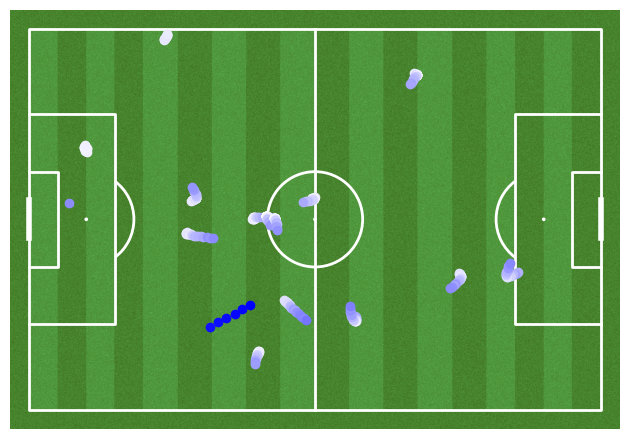

In [82]:
df = plot_aceleraciones_altas(a_max=4, use_df=df_backed_up)

In [84]:
# plot_aceleraciones_altas(a_max=4, use_df=df, include_acc=True)

In [85]:
df.head(100)

,Player Display Name,Time,Elapsed Time (s),Lat,Lon,Speed km/h,Instantaneous Acceleration Impulse,Heart Rate (bpm),basura,Lat_normalized,Lon_normalized,Speed m/s,Acceleration m/s^2
42,Fran Dennis,11:07:19.70,1780.500001,44.459459,48.852844,2.830002,1.900002,0.0,NaN,25.034874,12.025502,0.786112,NaN
42,Fran Dennis,11:07:19.80,1780.600000,44.459460,48.852845,2.660002,1.700001,0.0,NaN,25.106120,12.065598,0.738889,NaN
42,Fran Dennis,11:07:19.90,1780.700000,44.459461,48.852845,2.550002,1.100001,0.0,NaN,25.174191,12.086099,0.708334,NaN
42,Fran Dennis,11:07:20.00,1780.799999,44.459462,48.852844,2.470002,0.800001,0.0,NaN,25.266414,11.980405,0.686112,NaN
42,Fran Dennis,11:07:20.10,1780.899998,44.459464,48.852843,2.660002,1.900002,0.0,NaN,25.371478,11.869867,0.738889,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
99,Facundo Dominguez,11:33:41.70,3337.800005,44.459887,48.853205,11.540009,0.000000,0.0,NaN,58.275986,54.810841,3.205558,NaN
99,Facundo Dominguez,11:33:41.80,3337.900004,44.459891,48.853207,12.820010,12.800010,0.0,NaN,58.540564,55.037287,3.561114,NaN
99,Facundo Dominguez,11:33:41.90,3338.000003,44.459894,48.853211,16.450013,0.000000,0.0,NaN,58.826411,55.438547,4.569448,NaN
99,Facundo Dominguez,11:33:42.00,3338.100003,44.459897,48.853213,14.910012,15.400012,0.0,NaN,59.062301,55.753895,4.141670,NaN


In [39]:
grouped_df = df.groupby('Player Display Name').size()
grouped_df

Player Display Name
Arady                  61593
Facundo Dominguez      58734
Fran Dennis            59795
Mateo Soria            51062
Mauro Martinez         51865
Nahuel Lopez           51476
Rodrigo Espalter       50762
Rodriguez Luciano      61865
Roman                  60806
Sebastian Mysznajes    44791
dtype: int64

In [40]:
# grouped_df['Player Display Name']

Rodriguez Luciano  Total de puntos:  6
21


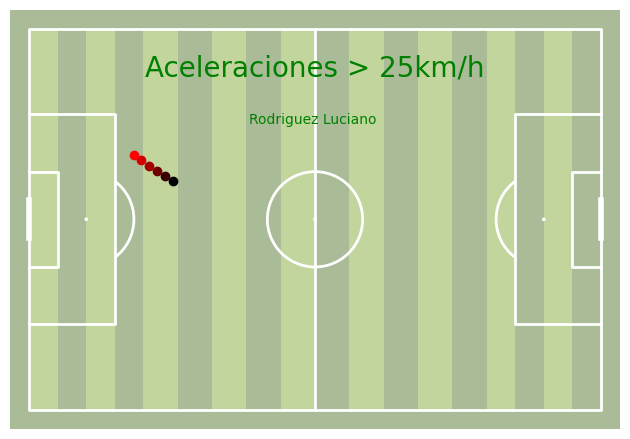

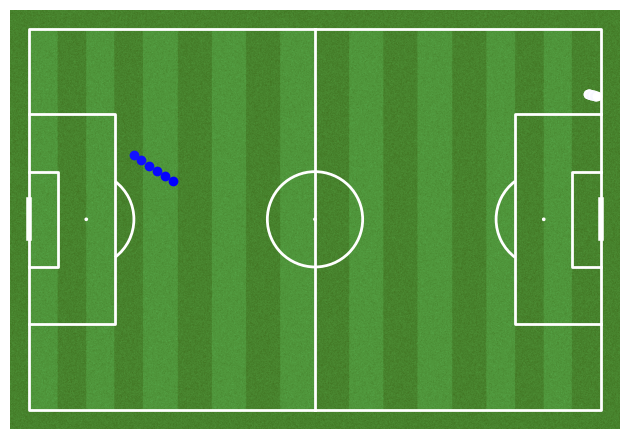

In [51]:
for name, group in df.groupby('Player Display Name'):
    # Filter the group based on 'Player Display Name'
    filtered_group = df[df['Player Display Name'] == name]
    plot_velocidades_altas(25, subtitle=name, use_df=filtered_group)
    plot_aceleraciones_altas(use_df=filtered_group)

Arady  Total de puntos:  22
Facundo Dominguez  Total de puntos:  19
Fran Dennis  Total de puntos:  10
Mateo Soria  Total de puntos:  0
Mauro Martinez  Total de puntos:  0
Nahuel Lopez  Total de puntos:  0
Rodrigo Espalter  Total de puntos:  15
Rodriguez Luciano  Total de puntos:  18
Roman  Total de puntos:  0
Sebastian Mysznajes Total de puntos:  0


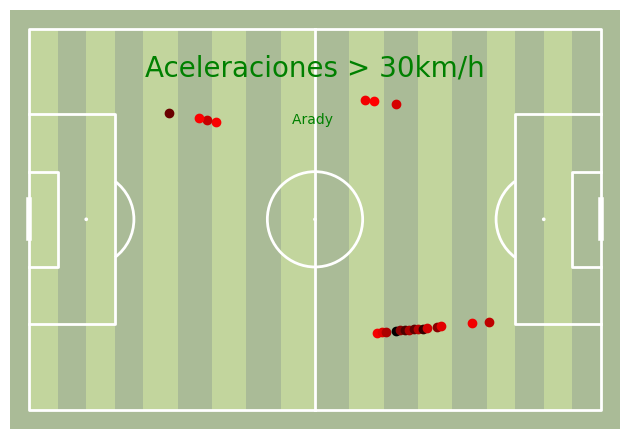

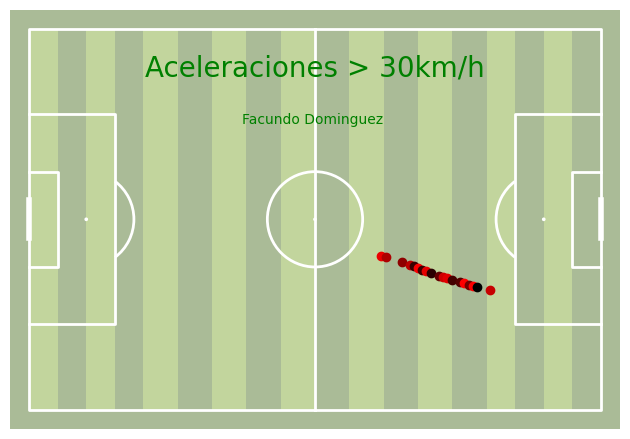

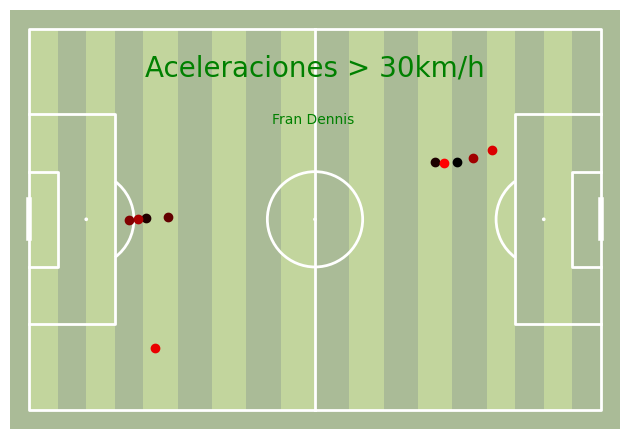

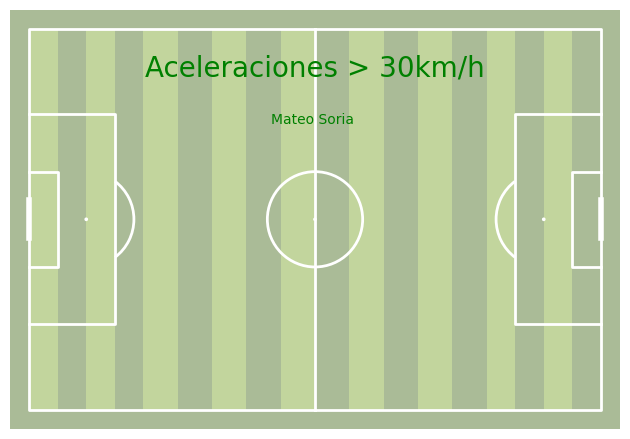

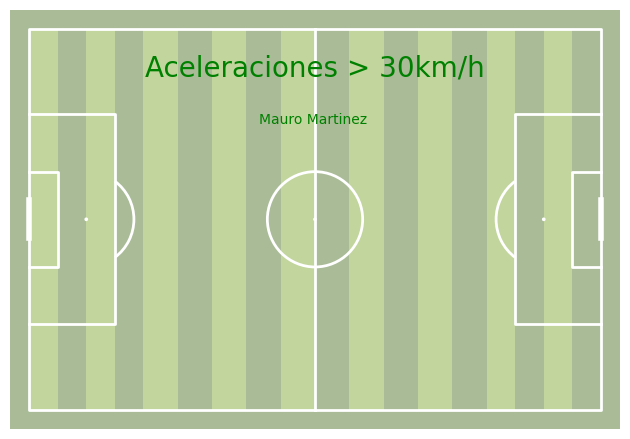

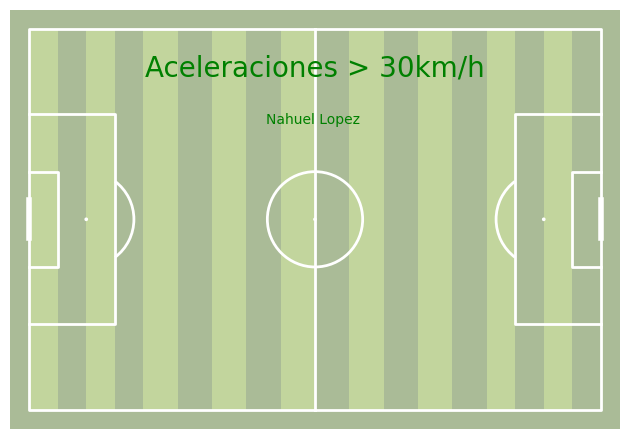

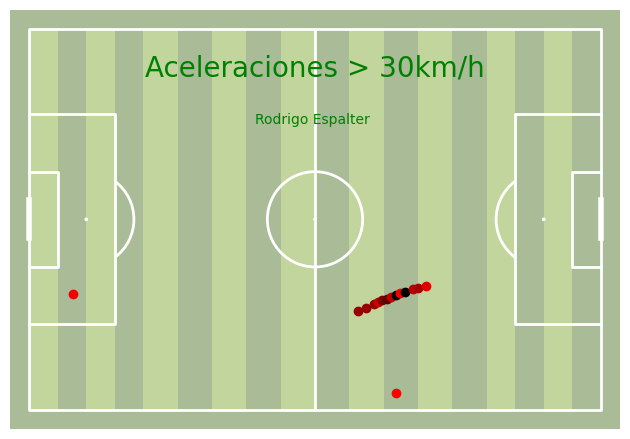

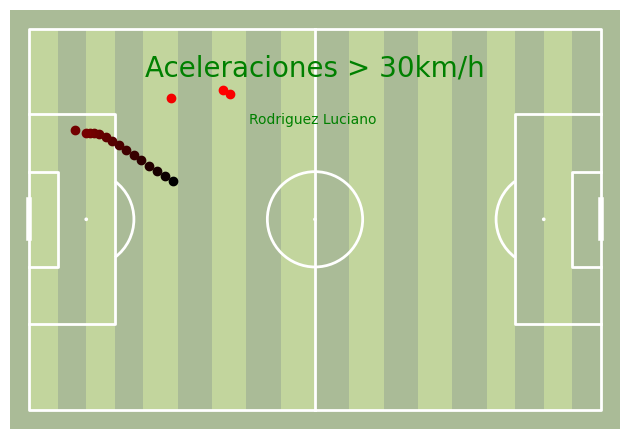

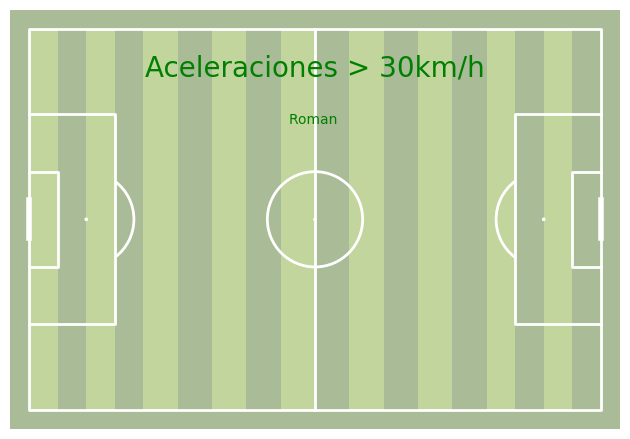

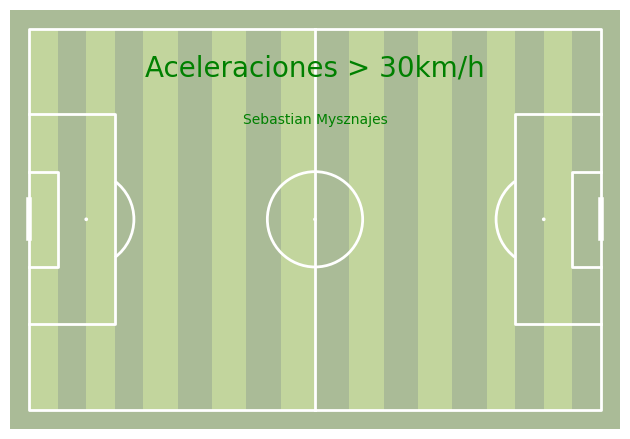

In [54]:
for name, group in df.groupby('Player Display Name'):
    # Filter the group based on 'Player Display Name'
    filtered_group = df[df['Player Display Name'] == name]
    plot_velocidades_altas(30, subtitle=name, use_df=filtered_group)